In [ ]:
'''
Never oversample your val and test data
Always try to select odd k value to avoid tie
model.fit not just loads the train data, but it also keeps it as the reference point for the actual predictions
    Hence it becomes important to train the scaled data if prediciton is on scaled data
        if you are predicting on non scaled data, train data should also be non scaled
Remember to handle
    1 -  imbalanced data
    2 - Scaling
Accuracy metric (model.score) for knn is correct-predictions/total
    This is correct in the following example because we are anyway doing oversampling

We can also use knn for null handling tool


make_pipeline: Pass all the steps to do complete process in a single step:imputing, scaling, oversampling,regresssion
    the last step should always be a regressor
    interesting: the object identifies a regressor with the idea that it should not have .tranform method but .predict method

bias-variance trade off - as we move from 1 to greater k, bias increases and variance decreases and hence movement from overfitting to underfitting

euclidean and manhattan distance is used for continuous and hamming (cosine) distance is used for categorical features

'''

''

# build model from sklearn (not from scratch)

In [20]:
import pandas as pd
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
import seaborn as sns

In [3]:
df=pd.read_csv(r'C:\Users\Mayank Bhatia\Documents\GitHub\DSML\14_ml_supervised_algorithms\14.2_ml_k_nearest_neighbors_2\multiclass.csv')

In [4]:
y=df['class']
x=df.drop(['class'],axis=1)

## Splitting into train and test

In [5]:
x_mid,x_test,y_mid,y_test =train_test_split(x,y,train_size=0.8,random_state=42)
x_train,x_val,y_train,y_val =train_test_split(x_mid,y_mid,train_size=0.8,random_state=42)

In [6]:
print(x.shape)
print(x_train.shape)
print(x_val.shape)
print(x_test.shape)
print(y.shape)
print(y_train.shape)
print(y_val.shape)
print(y_test.shape)

(440, 7)
(281, 7)
(71, 7)
(88, 7)
(440,)
(281,)
(71,)
(88,)


## Handling oversampling

In [7]:
smt=SMOTE()

In [8]:
x_train_sm,y_train_sm=smt.fit_resample(x_train,y_train)

In [9]:
print(x_train_sm.shape)
print(y_train_sm.shape)

(345, 7)
(345,)


## Scaling the oversampled data

In [10]:
scaler=StandardScaler()

In [11]:
x_train_sm_scaled=scaler.fit_transform(x_train_sm)
x_val_scaled=scaler.transform(x_val)
x_test_scaled=scaler.transform(x_test)

## Calling the model

In [12]:
classifier=KNeighborsClassifier(n_neighbors=5,metric='euclidean')

In [13]:
classifier.fit(x_train,y_train)
y_val_pred=classifier.predict(x_val)
print(classifier.score(x_val,y_val))


0.9295774647887324


In [ ]:
classifier.fit(x_train_sm_scaled,y_train_sm)

print(classifier.score(x_train_sm_scaled,y_train_sm))
print(classifier.score(x_val_scaled,y_val))
print(classifier.score(x_test_scaled,y_test))

classifier.fit(x_train_sm,y_train_sm)
print(classifier.score(x_train,y_train))
print(classifier.score(x_val,y_val))
print(classifier.score(x_test,y_test))

# INTERESTING THING TO NOTE HERE  IS THAT NON SCALED DATA IS GIVING BETTER ACCURACY HERE


0.9217391304347826
0.9154929577464789
0.875
0.9430604982206405
0.9154929577464789
0.8863636363636364


## Hyperparameter tuning

In [19]:
scores=[]
f1_scores=[]
for i in np.arange(1,51):
    model=KNeighborsClassifier(n_neighbors=i,metric='euclidean')
    model.fit(x_train_sm_scaled,y_train_sm)
    y_val_pred=model.predict(x_val_scaled)
    score_mid=model.score(x_val_scaled,y_val)
    f1_score_mid=f1_score(y_val,y_val_pred,average='weighted')

    scores.append(score_mid)
    f1_scores.append(f1_score_mid)


In [ ]:
print(f1_scores)
print(scores)
print(np.argmax(f1_scores))
# k value of 4 and 5 are showing the highest accuracy. WE will select number 5 to keep it odd

[0.8754339286876885, 0.8519836970541196, 0.8888548683404777, 0.9197021207706007, 0.9197021207706007, 0.9197021207706007, 0.9051829775646358, 0.9197021207706007, 0.9051829775646358, 0.8924823069692285, 0.9051829775646358, 0.8924823069692285, 0.8923223864068934, 0.8923223864068934, 0.8923223864068934, 0.879743257906977, 0.8644763316742561, 0.8363437581297936, 0.8363437581297936, 0.8231344589274778, 0.8363437581297936, 0.8231344589274778, 0.8231344589274778, 0.8231344589274778, 0.8356691814325489, 0.8231344589274778, 0.8505713918050004, 0.8368912534769747, 0.8488565623920125, 0.8488565623920125, 0.8488565623920125, 0.8368912534769747, 0.8488565623920125, 0.8368912534769747, 0.8488565623920125, 0.8355684345306288, 0.8192696924367804, 0.8192696924367804, 0.8323464939907782, 0.8323464939907782, 0.834729107796166, 0.8215122578044294, 0.8071763916834339, 0.8071763916834339, 0.8071763916834339, 0.8071763916834339, 0.8071763916834339, 0.7939000120944245, 0.7939000120944245, 0.7939000120944245]
[

<Axes: >

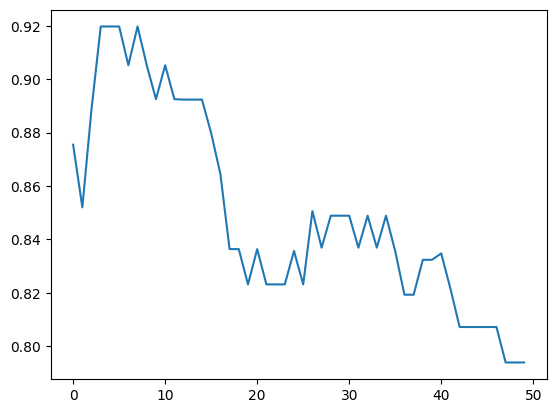

In [26]:
sns.lineplot(f1_scores)
# sns.lineplot(scores)

## Final scores

In [29]:
model=KNeighborsClassifier(n_neighbors=5,metric='euclidean')
model.fit(x_train_sm_scaled,y_train_sm)
print(model.score(x_test_scaled,y_test))

0.875


# KNN Imputer

In [56]:
from sklearn.impute import KNNImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [43]:
df_raw=pd.read_csv(r'C:\Users\Mayank Bhatia\Documents\GitHub\DSML\14_ml_supervised_algorithms\14.2_ml_k_nearest_neighbors_2\knn_imputation.csv')

In [44]:
df_raw=df_raw.drop(['Unnamed: 0'],axis=1)

In [45]:
df_raw.isnull().sum()

Region               8
Fresh               13
Milk                15
Grocery              9
Frozen               8
Detergents_Paper    10
Delicassen          11
dtype: int64

In [61]:
pl=make_pipeline(StandardScaler(),KNNImputer(n_neighbors=5,metric='nan_euclidean'))

In [64]:
df_raw_transformed=pd.DataFrame(pl.fit_transform(df_raw))

In [67]:
df_raw_transformed.isnull().sum()

0    0
1    0
2    0
3    0
4    0
5    0
6    0
dtype: int64

# Assignment

In [7]:
a=np.array([[4, 13, 2], [9, 8, 11], [14, 4, 2], [4, 12, 1], [2, 8, 3]])

In [9]:
np.sum(a)

np.int64(97)

In [10]:
point=[5,10,15]
X=[[4, 13, 2], [9, 8, 11], [14, 4, 2], [4, 12, 1], [2, 8, 3]]

point = np.array(point)
X = np.asarray(X)

In [32]:
p=1

In [41]:
np.round(np.power(np.sum(np.abs((X-point)**p),axis=1),(1/p)),2)

array([17., 10., 28., 17., 17.])

In [38]:
np.sum((X-point)**p,axis=1)

array([-11,  -2, -10, -13, -17])

In [39]:
np.sum(np.abs(point-X),axis=1)

array([17, 10, 28, 17, 17])

In [37]:
(point-X)

array([[ 1, -3, 13],
       [-4,  2,  4],
       [-9,  6, 13],
       [ 1, -2, 14],
       [ 3,  2, 12]])